# Linear Regression for Financial Returns

This notebook works through one pipeline on daily US equity data from WRDS (2019 to 2024):

1. Data Check
2. Return Distribution
3. Simple Linear Regression: Market Beta
4. Multiple Regression
5. Diagnostics and Limits

The notebook contains three kinds of cells:

- **Provided code**: complete code. Run it as it is.
- **Task**: a description of what to compute or plot, followed by an empty code cell. Write the code yourself; add more cells if needed. Most Tasks give reference values so you can check your implementation.
- **Question**: a written question. Answer it in prose in the **Answer** cell (a markdown cell) below it, using the numbers from your own results.

Save this notebook and `stock.csv` in the same folder before running it; the Setup cell reads `stock.csv` from that folder.

Run the cells from top to bottom. Later sections use variables created earlier.

Be prepared to explain everything you write, both code and answers, in the session.

## Setup

In [2]:
import pandas as pd

# Read the worksheet from the Excel file
stock_df = pd.read_excel(
    "stock.xlsx",
    sheet_name="stock.csv"
)

# Save it as a CSV file
stock_df.to_csv(
    "stock.csv",
    index=False
)

print("Converted stock.xlsx to stock.csv")

Converted stock.xlsx to stock.csv


In [3]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan

stock_df = pd.read_csv('stock.csv', parse_dates=['date'])
stock_df = stock_df.sort_values(['date', 'TSYMBOL'])
# RET contains non-numeric return codes; coerce them to NaN
stock_df['RET'] = pd.to_numeric(stock_df['RET'], errors='coerce')

# 1. Data Check

`PRC` is the closing price and `RET` is the daily return, both from CRSP. `PERMNO` is CRSP's permanent security identifier and `COMNAM` is the company name. The data was acquired from a reliable source, so it is accurate (almost surely).

In [4]:
prices = stock_df.pivot(index='date', columns='TSYMBOL', values='PRC')
returns = stock_df.pivot(index='date', columns='TSYMBOL', values='RET')
returns.head()

TSYMBOL,AAPL,AMZN,FB,GOOGL,META,METV,MSFT,NVDA,TSLA
date,,,,,,,,,
2019-01-02,0.001141,0.024741,0.035014,0.009302,NaN,NaN,-0.004430,0.020375,-0.068149
2019-01-03,-0.099607,-0.025242,-0.029039,-0.027696,NaN,NaN,-0.036788,-0.060417,-0.031472
2019-01-04,0.042689,0.050064,0.047138,0.051294,NaN,NaN,0.046509,0.064068,0.057697
2019-01-07,-0.002226,0.034353,0.000725,-0.001994,NaN,NaN,0.001275,0.052941,0.054361
2019-01-08,0.019063,0.016612,0.032452,0.008783,NaN,NaN,0.007251,-0.024895,0.001164


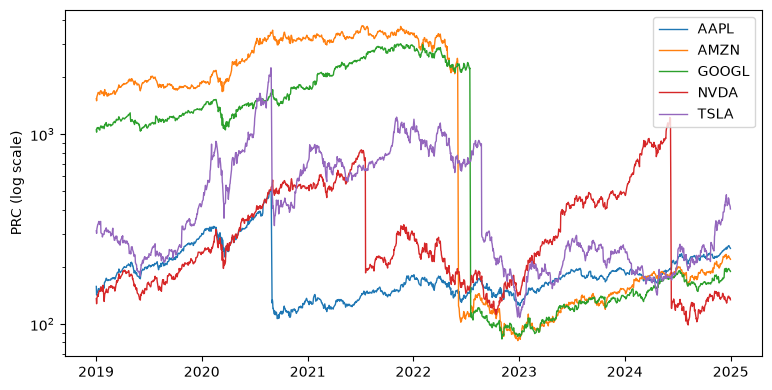

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for t in ['AAPL', 'AMZN', 'GOOGL', 'NVDA', 'TSLA']:
    ax.plot(prices.index, prices[t], lw=1, label=t)
ax.set_yscale('log')
ax.set_ylabel('PRC (log scale)')
ax.legend()
plt.show()

**Task 1A.** For every ticker (`TSYMBOL`), show the `PERMNO` and `COMNAM` behind it, together with the first date, the last date and the number of observations for each combination.

Reference: the table has 11 rows.

In [6]:
stock_df.head()

,PERMNO,date,NAMEENDT,SHRCD,EXCHCD,SICCD,NCUSIP,TICKER,COMNAM,SHRCLS,...,CFACPR,CFACSHR,OPENPRC,NUMTRD,RETX,vwretd,vwretx,ewretd,ewretx,sprtrn
3020,14593,2019-01-02,NaN,11,3,3571,3783310,AAPL,APPLE INC,NaN,...,4,4,154.89000,250910.0,0.001141,0.001796,0.001791,0.017126,0.017105,0.001269
5412,84788,2019-01-02,NaN,11,3,7370,2313510,AMZN,AMAZON COM INC,NaN,...,20,20,1465.19995,198679.0,0.024741,0.001796,0.001791,0.017126,0.017105,0.001269
1510,13407,2019-01-02,NaN,11,3,7375,30303M10,FB,FACEBOOK INC,A,...,1,1,128.99001,196687.0,0.035014,0.001796,0.001791,0.017126,0.017105,0.001269
8432,90319,2019-01-02,NaN,11,3,7375,02079K30,GOOGL,ALPHABET INC,A,...,20,20,1027.19995,39606.0,0.009302,0.001796,0.001791,0.017126,0.017105,0.001269
0,10107,2019-01-02,NaN,11,3,7370,59491810,MSFT,MICROSOFT CORP,NaN,...,1,1,99.55000,239618.0,-0.00443,0.001796,0.001791,0.017126,0.017105,0.001269


In [36]:
ticker_count = (
    stock_df
    .groupby(["TSYMBOL", "PERMNO", "COMNAM"], dropna=False)
    .agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        observations=("date", "size")
    )
)

ticker_count

first_date  last_date  observations
TSYMBOL PERMNO COMNAM                                                
AAPL    14593  APPLE INC          2019-01-02 2024-12-31          1510
AMZN    84788  AMAZON COM INC     2019-01-02 2024-12-31          1510
FB      13407  FACEBOOK INC       2019-01-02 2021-10-29           714
               META PLATFORMS INC 2021-11-01 2022-06-08           152
GOOGL   90319  ALPHABET INC       2019-01-02 2024-12-31          1510
META    13407  META PLATFORMS INC 2022-06-09 2024-12-31           644
        21413  LISTED FUNDS TRUST 2021-06-30 2022-01-28           148
METV    21413  LISTED FUNDS TRUST 2022-01-31 2024-12-31           734
MSFT    10107  MICROSOFT CORP     2019-01-02 2024-12-31          1510
NVDA    86580  NVIDIA CORP        2019-01-02 2024-12-31          1510
TSLA    93436  TESLA INC          2019-01-02 2024-12-31          1510

**Task 1B.** Compute daily returns from `PRC` and compare them with `RET`. Show the 10 largest absolute differences together with the date and ticker.

Reference: the largest absolute difference is about 0.969 (AMZN, 2022-06-06).

In [8]:
stock_df=stock_df.sort_values(['PERMNO',"date"])
stock_df["daily_return"]=(
    stock_df
    .groupby(["PERMNO"],dropna=False)["PRC"]
    .pct_change()
)
stock_df["abs_diff"]=(stock_df["daily_return"]-stock_df["RET"]).abs()
ans = (
    stock_df
    .nlargest(10, "abs_diff")
    [["abs_diff","date", "TSYMBOL"]]
)
ans

,abs_diff,date,TSYMBOL
6275,0.968946,2022-06-06,AMZN
9323,0.926649,2022-07-18,GOOGL
8290,0.906715,2024-06-10,NVDA
10361,0.900551,2020-08-31,TSLA
3439,0.775434,2020-08-31,AAPL
7563,0.743300,2021-07-20,NVDA
10861,0.664363,2022-08-25,TSLA
3046,0.004271,2019-02-08,AAPL
33,0.004253,2019-02-20,MSFT
3109,0.003837,2019-05-10,AAPL


**Question 1**

List every problem you found in the price data and in the ticker mapping. For each one, state how it would distort a regression if left untreated and how you would handle it.

**Answer:**
1. The Ticker FB begins with company name FACEBOOK but then changed to META. Later on this ticker change from FB to META. But these are essentially the same stock. I should use PERMNO to identify them instead of ticker.
2. There is sudden change in PRC as shown in the graph. This may because I did not handle the stock-split and use the raw data, which will definitely destort the regression since it does not reflect the real change in price. I need to acquire adjusted-data.
3. There is inconsistency between calculated daily return and RET. I cannot say for sure the reason behind because the inconstitency is not that large. Only 0.9% seems to be caused by rouding error. My approach will be stick with RET and do not calculate by myself. 


The rest of the notebook uses the six tickers below, their `RET`, and the S&P 500 daily return `sprtrn` as the market return `MKT`. Every later section reads from `data`, so leave it unchanged.

In [9]:
tickers = ['AAPL', 'AMZN', 'GOOGL', 'MSFT', 'NVDA', 'TSLA']
# sprtrn is identical for every stock on a given date
market = stock_df.groupby('date')['sprtrn'].first().rename('MKT')

data = returns[tickers].join(market).dropna()
data.describe().round(4)

,AAPL,AMZN,GOOGL,MSFT,NVDA,TSLA,MKT
count,1510.0000,1510.0000,1510.0000,1510.0000,1510.0000,1510.0000,1510.0000
mean,0.0014,0.0009,0.0010,0.0011,0.0030,0.0027,0.0006
std,0.0194,0.0215,0.0197,0.0183,0.0327,0.0406,0.0127
min,-0.1286,-0.1405,-0.1163,-0.1474,-0.1845,-0.2106,-0.1198
25%,-0.0079,-0.0104,-0.0085,-0.0076,-0.0154,-0.0181,-0.0046
50%,0.0015,0.0009,0.0014,0.0012,0.0032,0.0020,0.0009
75%,0.0119,0.0121,0.0108,0.0107,0.0204,0.0222,0.0069
max,0.1198,0.1354,0.1022,0.1422,0.2437,0.2192,0.0938


# 2. Return Distribution

Many standard results for regression assume normally distributed errors. We first look at how the returns themselves are distributed.

- **Shapiro-Wilk** compares the ordered sample with the expected order statistics of a normal distribution.
- **D'Agostino-Pearson** combines standardized skewness and kurtosis.
- **Jarque-Bera**: $JB = \frac{n}{6}\left(S^2 + \frac{(K-3)^2}{4}\right)$, where $S$ is skewness and $K$ is kurtosis.

`normal_sim` below is a simulated normal sample with the same length and standard deviation as AAPL, used as a reference.

In [10]:
normal_sim = pd.Series(np.random.default_rng(0).normal(0, data['AAPL'].std(), len(data)),
                       index=data.index, name='NORMAL_SIM')

**Task 2A.** For each of the six stocks, `MKT` and `normal_sim`, compute skewness, excess kurtosis, and the statistic and p-value of the three tests above. Collect the results in one table (`scipy.stats` has all of them).

Reference: AAPL has excess kurtosis 5.4959 and a Jarque-Bera statistic of 1900.42; `normal_sim` has a Jarque-Bera p-value of 0.2165.

In [37]:
series_to_test = {ticker: data[ticker] for ticker in tickers + ['MKT']}
series_to_test['NORMAL_SIM'] = normal_sim

rows = []
for name, series in series_to_test.items():
    values = series.dropna()
    shapiro = stats.shapiro(values)
    dagostino = stats.normaltest(values)
    jb = stats.jarque_bera(values)
    rows.append({
        'Series': name,
        'Skewness': stats.skew(values, bias=True),
        'Excess kurtosis': stats.kurtosis(values, fisher=True, bias=True),
        'Shapiro-Wilk statistic': shapiro.statistic,
        'Shapiro-Wilk p-value': shapiro.pvalue,
        "D'Agostino-Pearson statistic": dagostino.statistic,
        "D'Agostino-Pearson p-value": dagostino.pvalue,
        'Jarque-Bera statistic': jb.statistic,
        'Jarque-Bera p-value': jb.pvalue,
    })

normality_table = pd.DataFrame(rows).set_index('Series')
normality_table.round(4)


,Skewness,Excess kurtosis,Shapiro-Wilk statistic,Shapiro-Wilk p-value,D'Agostino-Pearson statistic,D'Agostino-Pearson p-value,Jarque-Bera statistic,Jarque-Bera p-value
Series,,,,,,,,
AAPL,-0.0095,5.4959,0.9396,0.0000,186.1488,0.0000,1900.4194,0.0000
AMZN,0.0642,4.3172,0.9567,0.0000,155.1573,0.0000,1173.7180,0.0000
GOOGL,-0.0318,4.1206,0.9483,0.0000,148.5085,0.0000,1068.5480,0.0000
MSFT,-0.0409,7.4339,0.9348,0.0000,229.9468,0.0000,3477.3669,0.0000
NVDA,0.3562,4.1867,0.9648,0.0000,180.6396,0.0000,1134.7336,0.0000
TSLA,0.2017,3.4924,0.9562,0.0000,138.5270,0.0000,777.6221,0.0000
MKT,-0.5446,14.0658,0.8737,0.0000,394.9009,0.0000,12522.5259,0.0000
NORMAL_SIM,-0.0800,0.1518,0.9984,0.1791,3.1156,0.2106,3.0606,0.2165


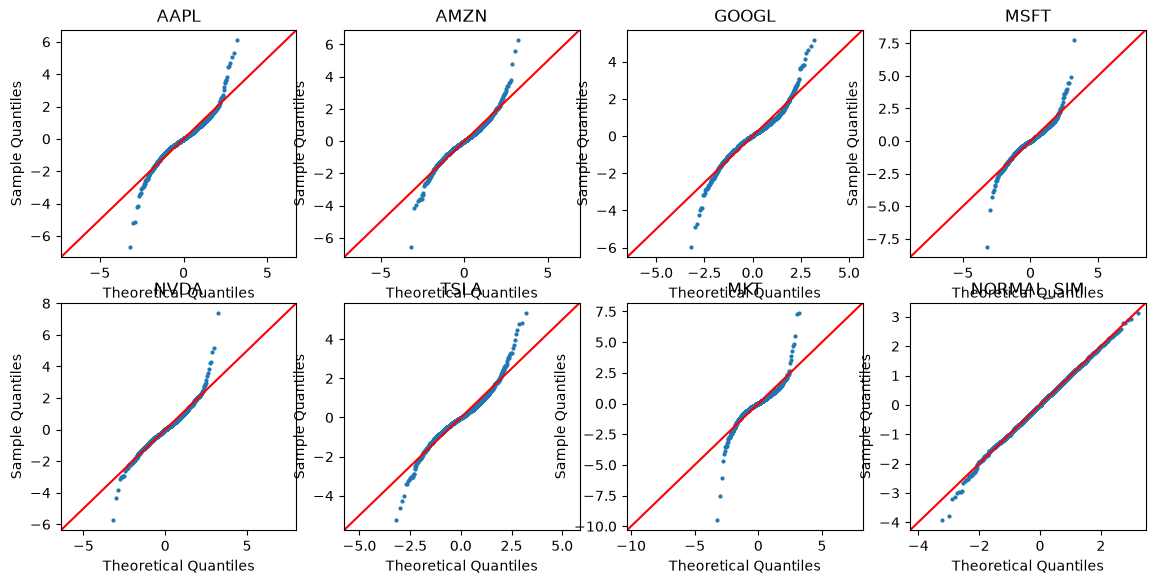

In [12]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6.5))
qq_series = {c: data[c] for c in tickers + ['MKT']} | {'NORMAL_SIM': normal_sim}
for ax, (name, s) in zip(axs.flat, qq_series.items()):
    sm.qqplot((s - s.mean()) / s.std(), line='45', ax=ax, markersize=2)
    ax.set_title(name)
plt.show()

**Task 2B.** Standardize each return series in `data` (subtract its mean, divide by its standard deviation). Then:

1. Count, for each series, the days with a standardized return beyond $\pm 4$, and compute the count a normal distribution would produce over the same number of days.
2. List every date on which at least one series is beyond $\pm 4$, showing which series.

Reference: the expected count under normality is about 0.10 days; AAPL has 11 such days; 35 dates are listed.

In [13]:
from IPython.display import display

# Standardize each column using its sample standard deviation (ddof=1).
standardized_returns = (data - data.mean()) / data.std()
extreme_mask = standardized_returns.abs() > 4

# P(|Z| > 4) for a standard normal variable includes both tails.
normal_tail_probability = 2 * stats.norm.sf(4)
extreme_counts = pd.DataFrame({
    'Observed days beyond ±4': extreme_mask.sum(),
    'Expected days under normality': data.count() * normal_tail_probability,
})
extreme_counts.index.name = 'Series'
display(extreme_counts)

# One row per date, with all series that crossed the threshold that day.
extreme_dates = (
    extreme_mask.loc[extreme_mask.any(axis=1)]
    .apply(lambda row: ', '.join(row.index[row]), axis=1)
    .rename('Series beyond ±4')
    .to_frame()
)
extreme_dates.index.name = 'Date'
with pd.option_context('display.max_rows', None):
    display(extreme_dates)


,Observed days beyond ±4,Expected days under normality
Series,,
AAPL,11,0.095647
AMZN,5,0.095647
GOOGL,9,0.095647
MSFT,8,0.095647
NVDA,7,0.095647
TSLA,9,0.095647
MKT,11,0.095647


,Series beyond ±4
Date,
2019-01-03,AAPL
2019-01-28,NVDA
2019-07-26,GOOGL
2019-10-24,TSLA
2020-02-03,TSLA
2020-02-05,TSLA
2020-03-02,AAPL
2020-03-09,"AAPL, MKT"
2020-03-12,"AAPL, GOOGL, MSFT, MKT"


**Question 2**

Using your numbers rather than general statements: how far from normal are these returns, and is the rejection driven mainly by skewness or by kurtosis? Look at the dates of the extreme days. Are they spread evenly over time or clustered, and what does that suggest about fitting one regression over the whole period?

**Answer:**

Almost all the stocks' return are far from normal distribution. The maximum Jarque-bera p-value is 1.385167e-169, which is far below threshold. So we can reject the hypothesis of normal distribution. The rejection mainly comes from excess kurtosis. The MKT excess kurtosis is around 14 while individual stocks' excess kurtosis range from 3.5 to 7.4. Although the skewness vaires, they are somewhere near zero, suggesting similar skewness as normal distribution. This idea of fat tail can be further comfirmed by the graph, which shows clearly that extreme values tends to deviate from normal distribution. Also, the number of extreme days further corroborate such idea.

The spread of extreme days often clustered as shown by 2020-03, 2020-04-06, 2022-11-10. So if we are going to fitting one regression for the whole period, it may not capable of capturing such market event. My approach will be segment whole period based on these extreme days and build regession model for each period.

# 3. Simple Linear Regression: Market Beta

We model the daily return of stock $i$ as a linear function of the market return:

$$r_{i,t} = \alpha_i + \beta_i \, m_t + \varepsilon_{i,t}$$

$\beta_i$ measures how much the stock moves with the market, and $\varepsilon_{i,t}$ is the part of the return the market does not explain.

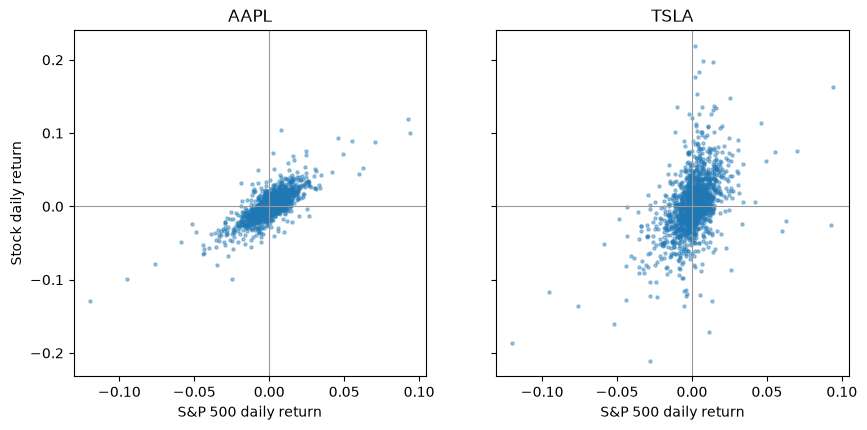

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, t in zip(axs, ['AAPL', 'TSLA']):
    ax.scatter(data['MKT'], data[t], s=5, alpha=0.4)
    ax.axhline(0, color='0.6', lw=0.8)
    ax.axvline(0, color='0.6', lw=0.8)
    ax.set_title(t)
    ax.set_xlabel('S&P 500 daily return')
axs[0].set_ylabel('Stock daily return')
plt.show()

## 3.1 Three routes to the same $\hat\beta$

**Task 3A.** Estimate AAPL's $\beta$ on `MKT` in three ways and print all three:

1. OLS with `statsmodels` (keep this fitted result as `res`; it is used again later)
2. $\hat\beta = \dfrac{\widehat{\mathrm{Cov}}(m, r)}{\widehat{\mathrm{Var}}(m)}$
3. $\begin{bmatrix}\hat\alpha \\ \hat\beta\end{bmatrix} = (X^\top X)^{-1} X^\top y$, where $X$ has a column of ones and a column of market returns

Reference: $\hat\beta = 1.198570$.

In [15]:
#OLS
X = sm.add_constant(data['MKT']) #y=mx+b set b neq 0
y = data['AAPL']
res = sm.OLS(y, X).fit()
print(res.params['MKT']) #Weird grammar for OLS...

#Statistic
beta1 = data['AAPL'].cov(data['MKT']) / data['MKT'].var()
print(beta1)

#Linear algebra

y = data['AAPL'].to_numpy()
market = data['MKT'].to_numpy()
X = np.column_stack([np.ones(len(market)), market])

alpha, beta = np.linalg.inv(X.T @ X) @ X.T @ y
print("alpha:", alpha)
print("beta:", beta)


1.1985699207513831
1.1985699207513831
alpha: 0.0006699832185785943
beta: 1.1985699207513827


**Task 3B.**

1. Fit the same regression **without** an intercept, $r_t = \beta m_t + \varepsilon_t$.
2. Modify the formula from Task 3A (route 2) so that it reproduces the no-intercept $\hat\beta$ exactly.
3. Add a constant `shift` to every market return and fit the regression with and without an intercept, for `shift` = 0, 0.01 and 0.05.

Reference: the no-intercept $\hat\beta$ is 1.2013 at `shift` = 0 and 0.7589 at `shift` = 0.01.

In [16]:
#OLS
X = data['MKT']
y = data['AAPL']
res = sm.OLS(y, X).fit()
print(res.params['MKT']) #Weird grammar for OLS...

#Modify formula
beta1 = (data['AAPL']*data['MKT']).sum() / (data['MKT']*data['MKT']).sum()
print(beta1)

#
shifts=[0,0.01,0.05]
for shift in shifts:
    X = data['MKT']+shift
    y = data['AAPL']
    res = sm.OLS(y, X).fit()
    print("shift=",shift,":",res.params['MKT'])

1.2012558356361374
1.2012558356361376
shift= 0 : 1.2012558356361374
shift= 0.01 : 0.7588743976208301
shift= 0.05 : 0.09746871774178771


**Question 3.1**

(a) Which part of the route 2 formula did you change to reproduce the no-intercept $\hat\beta$? What does this tell you about what the intercept does in OLS?

(b) Using your `shift` results, explain why dropping the intercept barely changes $\hat\beta$ for the original daily returns, and describe the kind of data for which dropping it would badly distort $\hat\beta$.

**Answer:**

(a) I think the difference is that I do not need to minus the $E(X)E(Y)$ term. But I don's see how this is meaningful statistically as I actually derive that formula by taking derivative.

(b) Because the original alpha is small, around 0.00067. If the stocks consistently outperform the market, then dropping intercept will badly distort $\hat\beta$

## 3.2 Six stocks, one market

Before doing Task 3C, write your predicted ranking of the six stocks by $\beta$ and by $R^2$ in the Answer cell of Question 3.2.

**Task 3C.**

1. Regress each of the six stocks on `MKT` and collect $\hat\beta$, $\mathrm{SE}(\hat\beta)$, $\hat\alpha$, the t-statistic of $\hat\alpha$, $R^2$ and the residual standard deviation in a table named `table`, indexed by ticker.
2. For simple regression, $R^2 = \hat\beta^2 \, \dfrac{\widehat{\mathrm{Var}}(m)}{\widehat{\mathrm{Var}}(r)}$. Check this numerically for TSLA.

Reference: TSLA has $\hat\beta = 1.5605$ and $R^2 = 0.2369$; MSFT has $\hat\beta = 1.1821$ and $R^2 = 0.6737$.

In [17]:
rows = {}

for ticker in tickers:
    X = sm.add_constant(data['MKT'])
    res = sm.OLS(data[ticker], X).fit()
    rows[ticker] = {
        'beta': res.params['MKT'],
        'SE(beta)': res.bse['MKT'],
        'alpha': res.params['const'],
        't(alpha)': res.tvalues['const'],
        'R²': res.rsquared,
        'Residual std': (res.mse_resid ** 0.5),
    }
table = pd.DataFrame.from_dict(rows, orient='index')
table.index.name = 'ticker'

tsla_beta = table.loc['TSLA', 'beta']
r2_from_variances = (
    tsla_beta**2 * data['MKT'].var() / data['TSLA'].var()
)
r2_ols = table.loc['TSLA', 'R²']
print(f"Variance formula: {r2_from_variances:.10f}")
print(f"OLS R²:           {r2_ols:.10f}")

table

Variance formula: 0.2369484748
OLS R²:           0.2369484748


,beta,SE(beta),alpha,t(alpha),R²,Residual std
ticker,,,,,,
AAPL,1.198570,0.024561,0.000670,2.149464,0.612282,0.012096
AMZN,1.097205,0.033300,0.000233,0.550677,0.418579,0.016401
GOOGL,1.142308,0.026981,0.000311,0.907889,0.543099,0.013288
MSFT,1.182122,0.021188,0.000386,1.434456,0.673654,0.010435
NVDA,1.790692,0.047737,0.001829,3.018591,0.482699,0.023511
TSLA,1.560534,0.072114,0.001739,1.899703,0.236948,0.035517


**Question 3.2**

(a) Your predicted rankings, written before Task 3C. Where were you wrong, and which column of `table` explains the gap?

(b) TSLA has a higher $\beta$ than MSFT but a much lower $R^2$. Using the identity in Task 3C and the numbers in your table, explain how both can be true. What does each number tell someone who holds TSLA?

**Answer:**

(a) 
Ranking of $\beta$ from high to low: TSLA, NVDA, AMZN, MSFT, AAPL, GOOGL
Actual Ranking: NVDA, TSLA, AAPL, MSFT, GOOGL, AMZN
I don't think I have a good idea about how this stocks moves with S&P 500...

Ranking of $R^2$ from low to high: TSLA, NVDA, MSFT, AAPL, GOOGL, AMZN
Actual Ranking: TSLA, AMZN, NVDA, GOOGL, AAPL, MSFT
I am wrong by assuming AMZN to be more close to market trend as I think its main business is online shopping which should correlate with the stock market (wealth effect). Obviously this logic is wrong since wealth effect needs time to take effect and I guess S&P 500 is more focus on tech company, which is not AMZN case.

$R^2$ column explains the gap. Some stocks' return is less consistently explained by the market.

(b) Tesla amlifies the market trend statistically, but its return is poorly explained by the market. Meanwhile, MSFT follows more closely to the market trend. Beta tells how this stocks will behave along with market trend. R^2 tells how trustworthy is such beta.



## 3.3 Precision of $\hat\beta$

**Task 3D.** Compute the standard error of AAPL's $\hat\beta$ from Task 3A yourself and compare it with the one `statsmodels` reports:

$$\mathrm{SE}(\hat\beta) = \sqrt{\frac{s^2}{\sum_t (m_t - \bar m)^2}}, \qquad s^2 = \frac{1}{n-2}\sum_t \hat\varepsilon_t^2$$

Reference: 0.024561.

In [18]:
X = data['MKT']
y = data['AAPL']
res = sm.OLS(y, X).fit()

m = data['MKT']
resid = res.resid
n = len(m)
s_squared = (resid**2).sum() / (n - 2)
se_beta = (s_squared / ((m - m.mean())**2).sum())**0.5

print(se_beta)

0.02459851130364461


The standard error claims to describe how much $\hat\beta$ would vary across repeated samples. With real data there is only one sample, so we simulate data where the true $\beta$ is known.

In [19]:
def simulate_beta(n, beta=1.2, alpha=0.0, sigma_m=0.0127, sigma_eps=0.012, n_sims=2000, seed=0):
    """Draw n_sims samples of size n from y = alpha + beta * m + eps.
    Return the OLS beta estimate and its reported standard error for each sample."""
    rng = np.random.default_rng(seed)
    m = rng.normal(0, sigma_m, size=(n_sims, n))
    eps = rng.normal(0, sigma_eps, size=(n_sims, n))
    y = alpha + beta * m + eps
    md = m - m.mean(axis=1, keepdims=True)
    yd = y - y.mean(axis=1, keepdims=True)
    sxx = (md ** 2).sum(axis=1)
    b = (md * yd).sum(axis=1) / sxx
    a = y.mean(axis=1) - b * m.mean(axis=1)
    e = y - a[:, None] - b[:, None] * m
    se = np.sqrt((e ** 2).sum(axis=1) / (n - 2) / sxx)
    return b, se

**Task 3E.**

1. Run `simulate_beta` with default parameters for `n` = 16, 64, 256 and 1024. For each `n`, report the mean and the standard deviation of the 2000 estimates and the mean reported SE, and plot the distributions of the estimates in one figure.
2. Run `simulate_beta` with `n` = 60, `sigma_m` equal to the standard deviation of `MKT`, and `sigma_eps` equal to AAPL's residual standard deviation from `table`. Report the fraction of simulated estimates at or above 1.4.

Reference: for `n` = 64, the standard deviation of the estimates is 0.1194; in part 2, the fraction is 0.0545.

,Mean beta,SD of beta estimates,Mean reported SE
n,,,
16,1.206692,0.260686,0.253792
64,1.202606,0.119424,0.119916
256,1.198263,0.060054,0.059218
1024,1.201123,0.029783,0.029555


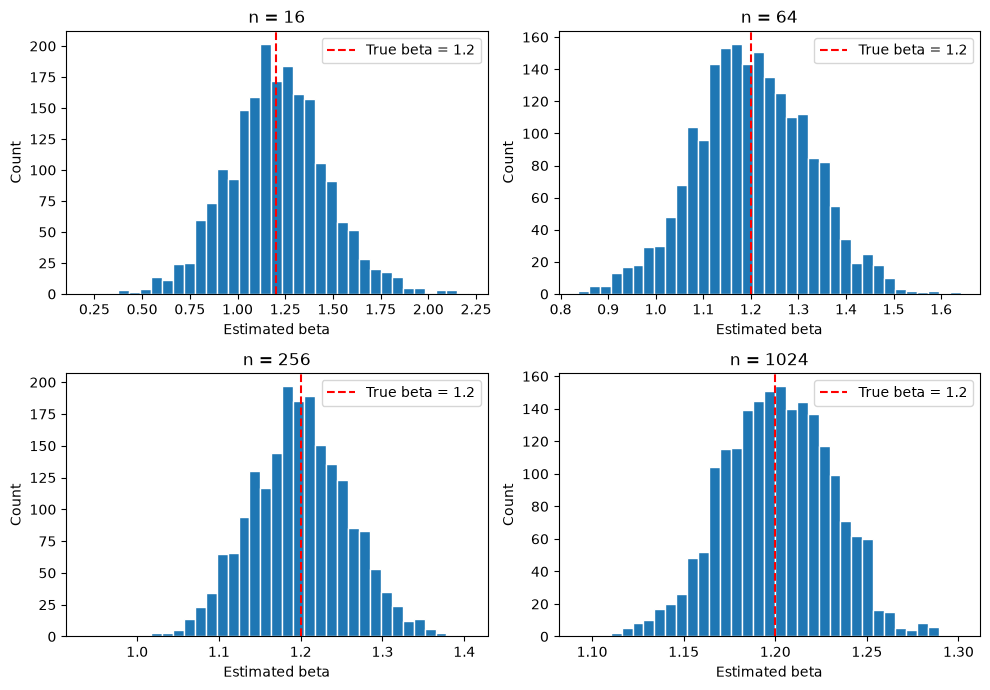

Fraction of estimates >= 1.4: 0.0545


In [20]:
summary = []
beta_samples = {}

for n in [16, 64, 256, 1024]:
    beta_hat, se_hat = simulate_beta(n)
    beta_samples[n] = beta_hat
    summary.append({
        'n': n,
        'Mean beta': beta_hat.mean(),
        'SD of beta estimates': beta_hat.std(ddof=1),
        'Mean reported SE': se_hat.mean(),
    })

summary = pd.DataFrame(summary).set_index('n')
display(summary.round(6))

# Plot all four distributions in one figure
fig, axs = plt.subplots(2, 2, figsize=(10, 7))

for ax, (n, beta_hat) in zip(axs.flat, beta_samples.items()):
    ax.hist(beta_hat, bins=35, edgecolor='white')
    ax.axvline(1.2, color='red', linestyle='--', label='True beta = 1.2')
    ax.set_title(f'n = {n}')
    ax.set_xlabel('Estimated beta')
    ax.set_ylabel('Count')
    ax.legend()

plt.tight_layout()
plt.show()

# Part 2
beta_60, se_60 = simulate_beta(
    n=60,
    sigma_m=data['MKT'].std(),
    sigma_eps=table.loc['AAPL', 'Residual std']
)

fraction_at_or_above_1_4 = (beta_60 >= 1.4).mean()
print(f'Fraction of estimates >= 1.4: {fraction_at_or_above_1_4:.4f}')

**Question 3.3**

(a) From part 1 of Task 3E, what happens to the spread of $\hat\beta$ each time $n$ is multiplied by 4? Connect this to the SE formula in Task 3D.

(b) Compare the standard deviation of the estimates with the mean reported SE. What does the reported SE claim to measure, and does the claim hold in this simulation?

(c) A colleague estimates AAPL's $\beta$ using only the last 60 trading days and gets 1.4. Using part 2 of Task 3E, decide whether this is evidence that AAPL's $\beta$ has changed.

**Answer:**

(a) The spread halfs when n multiplied by 4. This is becase SE takes the square root of 2 for $s^2$. So when $s^2$ is 1/4, $SE(\beta)$ is 1/2.

(b) Mean reported $SE(\beta)$ is very close to the standard deviation of the estimates. As name suggested(standard error of beta), SE claim to measure the uncertainty in the beta. That is when sampling repeatedly given true beta and market return, to what extend will the calculated \beta deviate from true value. As for 2000 times sampling, I believe SE did a good job in approximating that.

(c) Hypothesis:true beta is 1.2. With 60 trading days, the probability of getting more than 1.4 is 0.0545, greater than the p-value 0.05. Hence, there is not enough evidence to reject hypothesis.

# 4. Multiple Regression

## 4.1 Correlated regressors

The tech index proxy is the cross-sectional average of the six returns:

$$\text{TECH}_t = \frac{1}{6}\sum_{i} r_{i,t}$$

Regression 1 explains AAPL with two other tech stocks:

$$\text{AAPL}_t = \alpha + \beta_1 \, \text{MSFT}_t + \beta_2 \, \text{GOOGL}_t + \varepsilon_t$$

**Task 4A.** Construct the tech index as a separate Series named `tech` (do not add it to `data`). Show the correlation matrix of AAPL, MSFT, GOOGL, TECH and MKT.

Reference: the correlation between AAPL and MSFT is 0.735, and between MSFT and MKT is 0.821.

In [21]:
tech = data[tickers].mean(axis=1).rename('TECH')

corr_data = data[['AAPL', 'MSFT', 'GOOGL', 'MKT']].join(tech)
corr_data.corr().round(3)

,AAPL,MSFT,GOOGL,MKT,TECH
AAPL,1.000,0.735,0.639,0.782,0.805
MSFT,0.735,1.000,0.736,0.821,0.842
GOOGL,0.639,0.736,1.000,0.737,0.782
MKT,0.782,0.821,0.737,1.000,0.841
TECH,0.805,0.842,0.782,0.841,1.000


**Task 4B.**

1. Regress AAPL on each of the following sets of regressors and show the coefficients, their standard errors and $R^2$ in one table: MSFT only; GOOGL only; MSFT and GOOGL (Regression 1); MSFT, GOOGL and MKT.
2. Compute the variance inflation factor of MSFT, GOOGL and MKT in the last specification: $\mathrm{VIF}_j = \dfrac{1}{1 - R_j^2}$, where $R_j^2$ is the $R^2$ from regressing $x_j$ on the other regressors.

Reference: the MSFT coefficient is 0.7812, 0.6138 and 0.2744 in the specifications that include it; the VIF of MSFT is 3.47.

In [22]:
specs = {
    'MSFT only': ['MSFT'],
    'GOOGL only': ['GOOGL'],
    'MSFT + GOOGL (Regression 1)': ['MSFT', 'GOOGL'],
    'MSFT + GOOGL + MKT': ['MSFT', 'GOOGL', 'MKT'],
}

rows = []

for model_name, predictors in specs.items():
    X = sm.add_constant(data[predictors])
    fit = sm.OLS(data['AAPL'], X).fit()

    for term in fit.params.index:
        rows.append({
            'Model': model_name,
            'Term': term,
            'Coefficient': fit.params[term],
            'SE': fit.bse[term],
            'R²': fit.rsquared,
        })

regression_table = (
    pd.DataFrame(rows)
    .set_index(['Model', 'Term'])
)

display(regression_table.round(4))

Coefficient      SE      R²
Model                       Term                              
MSFT only                   const       0.0005  0.0003  0.5395
                            MSFT        0.7812  0.0186  0.5395
GOOGL only                  const       0.0008  0.0004  0.4079
                            GOOGL       0.6311  0.0196  0.4079
MSFT + GOOGL (Regression 1) const       0.0005  0.0003  0.5604
                            MSFT        0.6138  0.0268  0.5604
                            GOOGL       0.2111  0.0249  0.5604
MSFT + GOOGL + MKT          const       0.0005  0.0003  0.6399
                            MSFT        0.2744  0.0306  0.6399
                            GOOGL       0.0608  0.0240  0.6399
                            MKT         0.8048  0.0441  0.6399

In [23]:
predictors = ['MSFT', 'GOOGL', 'MKT']
vif_rows = []

for predictor in predictors:
    others = [x for x in predictors if x != predictor]
    X_other = sm.add_constant(data[others])
    aux_fit = sm.OLS(data[predictor], X_other).fit()

    vif_rows.append({
        'Predictor': predictor,
        'Auxiliary R²': aux_fit.rsquared,
        'VIF': 1 / (1 - aux_fit.rsquared),
    })

vif_table = pd.DataFrame(vif_rows).set_index('Predictor')
display(vif_table.round(4))

#Look at the MKT, it is largely explained by MSFT and GOOGL, hence, itself does not contribute much to the model. Hence, the SE of market coefficient is also high, suggesting similar uncertainty.

,Auxiliary R²,VIF
Predictor,,
MSFT,0.7115,3.4664
GOOGL,0.5961,2.4759
MKT,0.7120,3.4727


The simulation below has two regressors whose correlation is `rho`; both true coefficients equal 1. With `omit_x2=True`, $x_2$ is left out of the regression.

In [24]:
def simulate_collinear(rho, omit_x2=False, n=250, n_sims=2000, seed=0):
    """y = x1 + x2 + eps with corr(x1, x2) = rho.
    Return the OLS estimates of the x1 coefficient and their reported SE.
    If omit_x2 is True, y is regressed on x1 only."""
    rng = np.random.default_rng(seed)
    L = np.linalg.cholesky([[1.0, rho], [rho, 1.0]])
    xx = rng.standard_normal((n_sims, n, 2)) @ L.T
    y = xx.sum(axis=2) + rng.standard_normal((n_sims, n))
    regressors = xx[:, :, :1] if omit_x2 else xx
    X = np.concatenate([np.ones((n_sims, n, 1)), regressors], axis=2)
    XtX_inv = np.linalg.inv(X.transpose(0, 2, 1) @ X)
    b = (XtX_inv @ X.transpose(0, 2, 1) @ y[:, :, None])[:, :, 0]
    e = y - (X @ b[:, :, None])[:, :, 0]
    s2 = (e ** 2).sum(axis=1) / (n - X.shape[2])
    return b[:, 1], np.sqrt(s2 * XtX_inv[:, 1, 1])

**Task 4C.** Run `simulate_collinear` for `rho` = 0, 0.5, 0.8, 0.95 and 0.99, both with and without `omit_x2`. For each case, report the mean and the standard deviation of the $x_1$ estimates and the mean reported SE in one table.

Reference: at `rho` = 0.8, the mean estimate is 0.9971 with both regressors and 1.7979 with $x_2$ omitted.

In [25]:
rows = []

for rho in [0, 0.5, 0.8, 0.95, 0.99]:
    for omit_x2 in [False, True]:
        beta_hat, se_hat = simulate_collinear(rho, omit_x2=omit_x2)
        rows.append({
            'rho': rho,
            'omit_x2': omit_x2,
            'Mean x1 estimate': beta_hat.mean(),
            'SD of estimates': beta_hat.std(ddof=1),
            'Mean reported SE': se_hat.mean(),
        })

collinear_table = pd.DataFrame(rows)
collinear_table.round(4)
#Interesting table result

,rho,omit_x2,Mean x1 estimate,SD of estimates,Mean reported SE
0,0.00,False,0.9993,0.0637,0.0635
1,0.00,True,0.9970,0.0922,0.0897
2,0.50,False,0.9983,0.0723,0.0732
3,0.50,True,1.4973,0.0860,0.0839
4,0.80,False,0.9971,0.1048,0.1057
5,0.80,True,1.7979,0.0753,0.0739
6,0.95,False,0.9943,0.2038,0.2032
7,0.95,True,1.9486,0.0671,0.0664
8,0.99,False,0.9878,0.4547,0.4500
9,0.99,True,1.9889,0.0643,0.0640


**Question 4.1**

Using Tasks 4B and 4C: why does the coefficient on MSFT change when GOOGL or the market is added? When regressors are highly correlated, is the estimate biased, imprecise, or both? Distinguish what happens when a correlated regressor is omitted from what happens when it is included, with numbers from the simulation.

**Answer:**
The correlation between MSFT and GOOGL is 0.736	and between MSFT and MKT is 0.821. Hence, when GOOGL is added, the separate effects by MSFT is less and also harder to distinguish(that's why SE increase!). When including a highly correlated predictor, the estimate becomes imprecise since SE increases from 0.0637 to 0.4547. If it is omitted, the estimate becomes biased since the existing predictor need to account for the omitted predictor's effect now. It is about $1+\rho$ as shown by simulation.

## 4.2 Excess returns over the index

Regression 2 subtracts the tech index from every return:

$$(\text{AAPL}_t - \text{TECH}_t) = \alpha + \beta_1 (\text{MSFT}_t - \text{TECH}_t) + \beta_2 (\text{GOOGL}_t - \text{TECH}_t) + \varepsilon_t$$

**Task 4D.**

1. Compute the excess return of each of the six stocks over `tech`, estimate Regression 2, and show its coefficients, standard errors and $R^2$ next to those of Regression 1.
2. Compute, for each date, the sum of the six excess returns, and report the largest absolute value.
3. Show the correlation matrix of the six excess returns.

Reference: Regression 2 has $R^2 = 0.0937$ and an MSFT coefficient of 0.3228.

In [26]:
# Excess return for each stock, relative to the six-stock average
excess = data[tickers].sub(tech, axis=0)

# Regression 1: raw returns
fit_1 = sm.OLS(
    data['AAPL'],
    sm.add_constant(data[['MSFT', 'GOOGL']])
).fit()

# Regression 2: excess returns over TECH
fit_2 = sm.OLS(
    excess['AAPL'],
    sm.add_constant(excess[['MSFT', 'GOOGL']])
).fit()

# One comparison table: coefficients, standard errors, and R²
regression_comparison = pd.concat({
    'Regression 1': pd.DataFrame({
        'Coefficient': fit_1.params,
        'SE': fit_1.bse,
    }),
    'Regression 2': pd.DataFrame({
        'Coefficient': fit_2.params,
        'SE': fit_2.bse,
    }),
}, axis=1)

regression_comparison.loc['R²'] = [
    fit_1.rsquared, float('nan'),
    fit_2.rsquared, float('nan'),
]

display(regression_comparison.round(4))

# Sum of the six excess returns on each date
excess_row_sum = excess.sum(axis=1)
print('Largest absolute daily sum:', excess_row_sum.abs().max())

# Correlations among the six excess-return series
display(excess.corr().round(4))

Regression 1         Regression 2        
       Coefficient      SE  Coefficient      SE
const       0.0005  0.0003      -0.0001  0.0003
MSFT        0.6138  0.0268       0.3228  0.0296
GOOGL       0.2111  0.0249       0.0465  0.0246
R²          0.5604     NaN       0.0937     NaN

Largest absolute daily sum: 8.326672684688674e-17


,AAPL,AMZN,GOOGL,MSFT,NVDA,TSLA
AAPL,1.0000,-0.0138,0.1489,0.3026,-0.2770,-0.4091
AMZN,-0.0138,1.0000,0.1601,0.1595,-0.2500,-0.4289
GOOGL,0.1489,0.1601,1.0000,0.3485,-0.2791,-0.5297
MSFT,0.3026,0.1595,0.3485,1.0000,-0.2083,-0.5934
NVDA,-0.2770,-0.2500,-0.2791,-0.2083,1.0000,-0.2404
TSLA,-0.4091,-0.4289,-0.5297,-0.5934,-0.2404,1.0000


**Question 4.2**

Compare Regression 1 and Regression 2. Using the row sums and the correlation matrix from Task 4D, explain how much of Regression 2's result follows mechanically from the way excess returns are constructed rather than from the stocks' behaviour. How would you construct the index to remove this effect?

**Answer:**
The row sum is basically 0, which is what you would expect based since tech is just average of all six. Due to this construction, the correlation between two stocks are distorted. Hence, low R^2 in regression 2 does not really suggest anything. Also, TECH includes 1/6 of Y already. So basically you are using Y itself to predict Y, which contains circulating problem when doing extrapolate. My approach to construct the index would be:

(1) Use bigger universe to account for tech companies, just like using S&P 500 to account for market. So even individual company is already included in the index, the effect would not be that significant. 

(2) Construct separate tech index for each. For example, for AAPL, I will average NVDA, TSLA, AMZN as tech index. 

(3) Maybe we can use previous day Tech index. So the excess return has economic meaning of "how does this stock outperform yesterday tech industry?". In this case, it can still account for some tech trend(although not up to date) while avoid the problem mentioned before.

# 5. Diagnostics and Limits

Unless stated otherwise, this section uses the AAPL on `MKT` regression `res` from Task 3A.

## 5.1 Residuals and standard errors

**Task 5A.**

1. For AAPL's raw returns and for the residuals of `res`, compute skewness, excess kurtosis and the Jarque-Bera statistic and p-value, and draw the two QQ-plots side by side.
2. Group the squared residuals by deciles of $|m_t|$ and plot the mean squared residual of each decile against the mean $|m_t|$ of that decile.
3. Run a Breusch-Pagan test that regresses the squared residuals on $|m_t|$ (`het_breuschpagan` with a constant and $|m_t|$ as the explanatory variables).

Reference: the residual skewness is 0.4755; the Breusch-Pagan statistic is 16.62.

,Skewness,Excess kurtosis,Jarque-Bera,JB p-value
Series,,,,
AAPL returns,-0.009545,5.495906,1900.419445,0.0
AAPL-MKT residuals,0.475461,5.664768,2075.863174,0.0


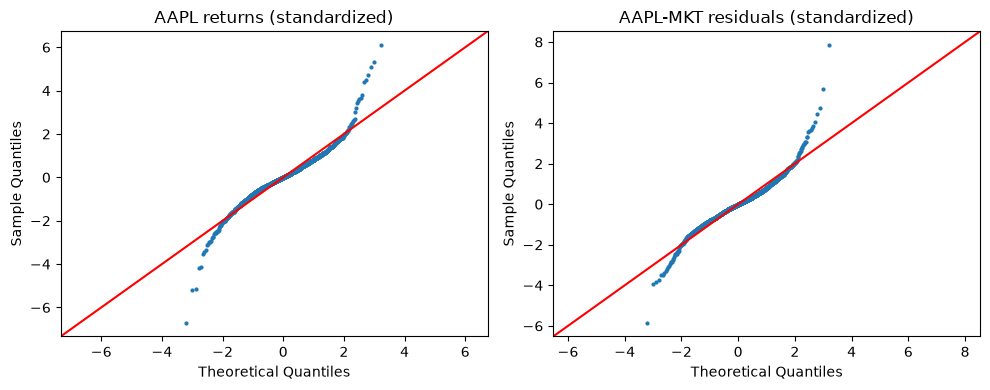

,mean_abs_MKT,mean_squared_residual
decile,,
1,0.000475,0.000083
2,0.001417,0.000081
3,0.002420,0.000117
4,0.003544,0.000132
5,0.005028,0.000127
6,0.006771,0.000137
7,0.008498,0.000184
8,0.011057,0.000184
9,0.014753,0.000154


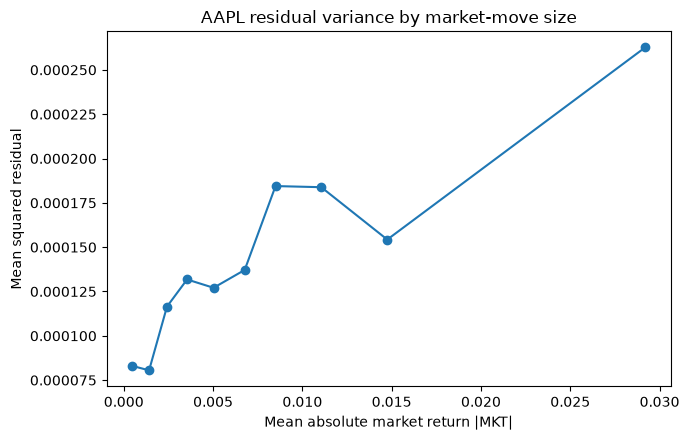

LM statistic    16.622268
LM p-value       0.000046
F statistic     16.785023
F p-value        0.000044
Name: Breusch-Pagan, dtype: float64

In [27]:
res = sm.OLS(data['AAPL'], sm.add_constant(data['MKT'])).fit()

# 1. Distribution statistics for raw AAPL returns and regression residuals
series_5a = {
    'AAPL returns': data['AAPL'],
    'AAPL-MKT residuals': res.resid,
}
rows_5a = []
for name, series in series_5a.items():
    jb = stats.jarque_bera(series)
    rows_5a.append({
        'Series': name,
        'Skewness': stats.skew(series),
        'Excess kurtosis': stats.kurtosis(series, fisher=True),
        'Jarque-Bera': jb.statistic,
        'JB p-value': jb.pvalue,
    })
stats_5a = pd.DataFrame(rows_5a).set_index('Series')
display(stats_5a)

# Side-by-side Q-Q plots
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, series) in zip(axs, series_5a.items()):
    # Standardize before comparing with theoretical N(0, 1) quantiles.
    standardized = (series - series.mean()) / series.std()
    sm.qqplot(standardized, line='45', ax=ax, markersize=2)
    ax.set_title(f'{name} (standardized)')
plt.tight_layout()
plt.show()

# 2. Mean squared residual by decile of absolute market return
abs_mkt = data['MKT'].abs().rename('abs_MKT')
squared_resid = (res.resid ** 2).rename('squared_residual')
decile_data = pd.concat([abs_mkt, squared_resid], axis=1)
decile_data['decile'] = pd.qcut(decile_data['abs_MKT'], 10, labels=False) + 1
decile_summary = decile_data.groupby('decile').agg(
    mean_abs_MKT=('abs_MKT', 'mean'),
    mean_squared_residual=('squared_residual', 'mean'),
)
display(decile_summary)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(decile_summary['mean_abs_MKT'], decile_summary['mean_squared_residual'], marker='o')
ax.set_xlabel('Mean absolute market return |MKT|')
ax.set_ylabel('Mean squared residual')
ax.set_title('AAPL residual variance by market-move size')
plt.tight_layout()
plt.show()

# 3. Breusch-Pagan test: squared residuals on a constant and |MKT|
bp_lm, bp_lm_pvalue, bp_f, bp_f_pvalue = het_breuschpagan(
    res.resid,
    sm.add_constant(abs_mkt),
)
bp_results = pd.Series({
    'LM statistic': bp_lm,
    'LM p-value': bp_lm_pvalue,
    'F statistic': bp_f,
    'F p-value': bp_f_pvalue,
}, name='Breusch-Pagan')
display(bp_results)


**Task 5B.** Classical standard errors assume the error variance is constant; heteroskedasticity-robust (HC1) standard errors do not. For each of the six stocks, report the classical and the HC1 standard error of $\hat\beta$ and their ratio (`fit(cov_type='HC1')` in `statsmodels`).

Reference: the HC1 / classical ratio is 1.2676 for AAPL and 2.0849 for AMZN.

In [28]:
rows = []

for ticker in tickers:
    X = sm.add_constant(data['MKT'])
    fit = sm.OLS(data[ticker], X).fit()
    hc1_fit = fit.get_robustcov_results(cov_type='HC1')

    beta_index = list(fit.params.index).index('MKT')
    classical_se = fit.bse['MKT']
    hc1_se = hc1_fit.bse[beta_index]

    rows.append({
        'Ticker': ticker,
        'Classical SE(beta)': classical_se,
        'HC1 SE(beta)': hc1_se,
        'HC1 / classical': hc1_se / classical_se,
    })

se_table = pd.DataFrame(rows).set_index('Ticker')
se_table.round(4)

,Classical SE(beta),HC1 SE(beta),HC1 / classical
Ticker,,,
AAPL,0.0246,0.0311,1.2676
AMZN,0.0333,0.0694,2.0849
GOOGL,0.0270,0.0343,1.2708
MSFT,0.0212,0.0281,1.3248
NVDA,0.0477,0.0613,1.2846
TSLA,0.0721,0.1067,1.4790


The simulation below has a true $\beta$ of 1.2 but errors that break the classical assumptions. `het` makes the error variance grow with $|m_t|$; `df` draws the errors from a Student-t distribution with `df` degrees of freedom (fat tails) instead of a normal distribution.

In [29]:
def simulate_beta_broken(n=1500, beta=1.2, sigma_m=0.0127, sigma_eps=0.012, het=0.0, df=None, n_sims=2000, seed=0):
    """Return beta estimates, classical SEs and HC1 SEs when the errors violate the classical assumptions."""
    rng = np.random.default_rng(seed)
    m = rng.normal(0, sigma_m, size=(n_sims, n))
    shock = rng.standard_t(df, size=(n_sims, n)) / np.sqrt(df / (df - 2)) if df else rng.standard_normal((n_sims, n))
    scale = 1 + het * np.abs(m) / sigma_m
    eps = sigma_eps * shock * scale / np.sqrt((scale ** 2).mean())
    y = beta * m + eps
    md = m - m.mean(axis=1, keepdims=True)
    sxx = (md ** 2).sum(axis=1)
    b = (md * (y - y.mean(axis=1, keepdims=True))).sum(axis=1) / sxx
    e = y - (y.mean(axis=1) - b * m.mean(axis=1))[:, None] - b[:, None] * m
    se_classic = np.sqrt((e ** 2).sum(axis=1) / (n - 2) / sxx)
    se_hc1 = np.sqrt(n / (n - 2) * (md ** 2 * e ** 2).sum(axis=1)) / sxx
    return b, se_classic, se_hc1

**Task 5C.** Run `simulate_beta_broken` for the four combinations of `het` in {0, 2} and `df` in {None, 3}. For each, report the mean and the standard deviation of the estimates, the mean classical SE and the mean HC1 SE in one table.

Reference: with `het` = 2 and `df` = None, the standard deviation of the estimates is 0.0374, the mean classical SE is 0.0244 and the mean HC1 SE is 0.0374.

In [30]:
rows = []

for het in [0, 2]:
    for df in [None, 3]:
        beta_hat, se_classic, se_hc1 = simulate_beta_broken(
            het=het,
            df=df,
        )
        rows.append({
            'het': het,
            'df': df,
            'Mean beta estimate': beta_hat.mean(),
            'SD of estimates': beta_hat.std(ddof=1),
            'Mean classical SE': se_classic.mean(),
            'Mean HC1 SE': se_hc1.mean(),
        })

simulation_table = pd.DataFrame(rows).set_index(['het', 'df'])
simulation_table.round(4)

Mean beta estimate  SD of estimates  Mean classical SE  Mean HC1 SE
het df                                                                      
0   NaN              1.1996           0.0247             0.0244       0.0244
    3.0              1.1998           0.0240             0.0242       0.0239
2   NaN              1.1989           0.0375             0.0244       0.0374
    3.0              1.1995           0.0369             0.0240       0.0364

**Question 5.1**

Compare the results for AAPL's raw returns and its residuals in Task 5A, then use the rest of Task 5A, Task 5B and Task 5C. When the classical assumptions fail, which becomes unreliable: $\hat\beta$ itself, or its standard error? In which direction is the classical SE wrong for this data? Use numbers.

**Answer:**

$\hat\beta$ itself is still reliable but the classical SE will underestimate the certainty of the slope when error grows with MKT. When het is 0, the simulated SD is 0.0375 and 0.0369 respectively, but mean classical SE is only 0.0244 and 0.0240. The mean HC1 is more close to simualted SD.

As for degree of freedom, larger df leads to fatter tail distribution of error, but I don't see any clear connection with SE.


## 5.2 Stability of $\beta$ over time

A rolling estimate re-fits the regression on a moving window of the most recent days.

**Task 5D.** Compute AAPL's rolling $\beta$ on `MKT` as the rolling covariance divided by the rolling variance, with windows of 60 and 252 trading days. Plot both together with the full-sample $\hat\beta$.

Reference: the 60-day estimate ranges from 0.644 to 2.009; the 252-day estimate ranges from 0.939 to 1.565.

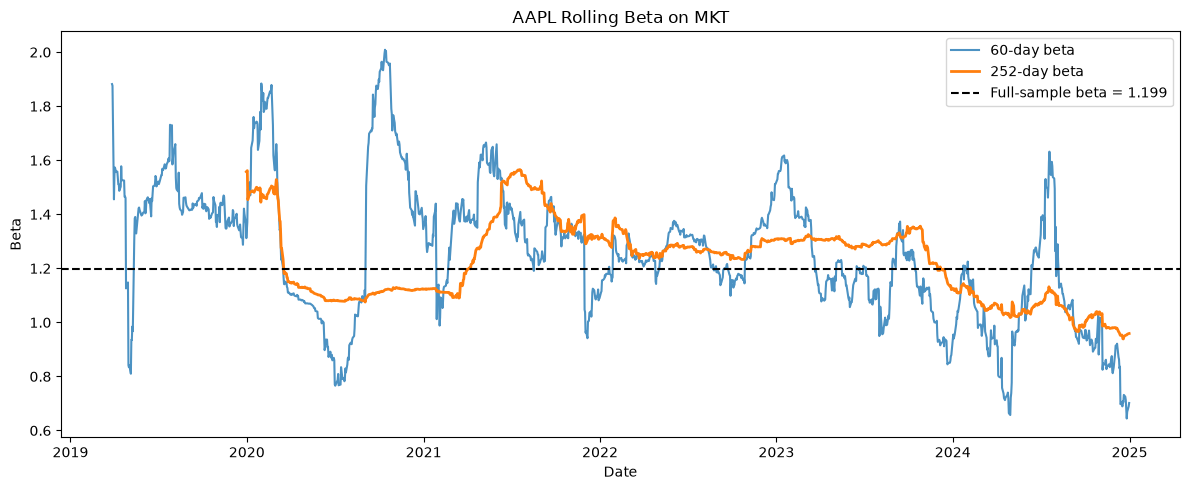

60-day beta range:  0.644 to 2.009
252-day beta range: 0.939 to 1.565


In [31]:
m = data['MKT']
r = data['AAPL']

beta_full = r.cov(m) / m.var()

beta_60 = r.rolling(60).cov(m) / m.rolling(60).var()
beta_252 = r.rolling(252).cov(m) / m.rolling(252).var()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(data.index, beta_60, label='60-day beta', alpha=0.8)
ax.plot(data.index, beta_252, label='252-day beta', linewidth=2)
ax.axhline(beta_full, color='black', linestyle='--',
           label=f'Full-sample beta = {beta_full:.3f}')

ax.set_title('AAPL Rolling Beta on MKT')
ax.set_xlabel('Date')
ax.set_ylabel('Beta')
ax.legend()
plt.tight_layout()
plt.show()

print(f'60-day beta range:  {beta_60.min():.3f} to {beta_60.max():.3f}')
print(f'252-day beta range: {beta_252.min():.3f} to {beta_252.max():.3f}')

**Question 5.2**

Is AAPL's $\beta$ stable? Using Task 5D and Task 3E, separate movements that are consistent with sampling noise from movements that look like genuine change, and identify when the largest movements occurred. How does the window length trade off between the two? If you had to hedge AAPL's market exposure today, which estimate would you use and why?

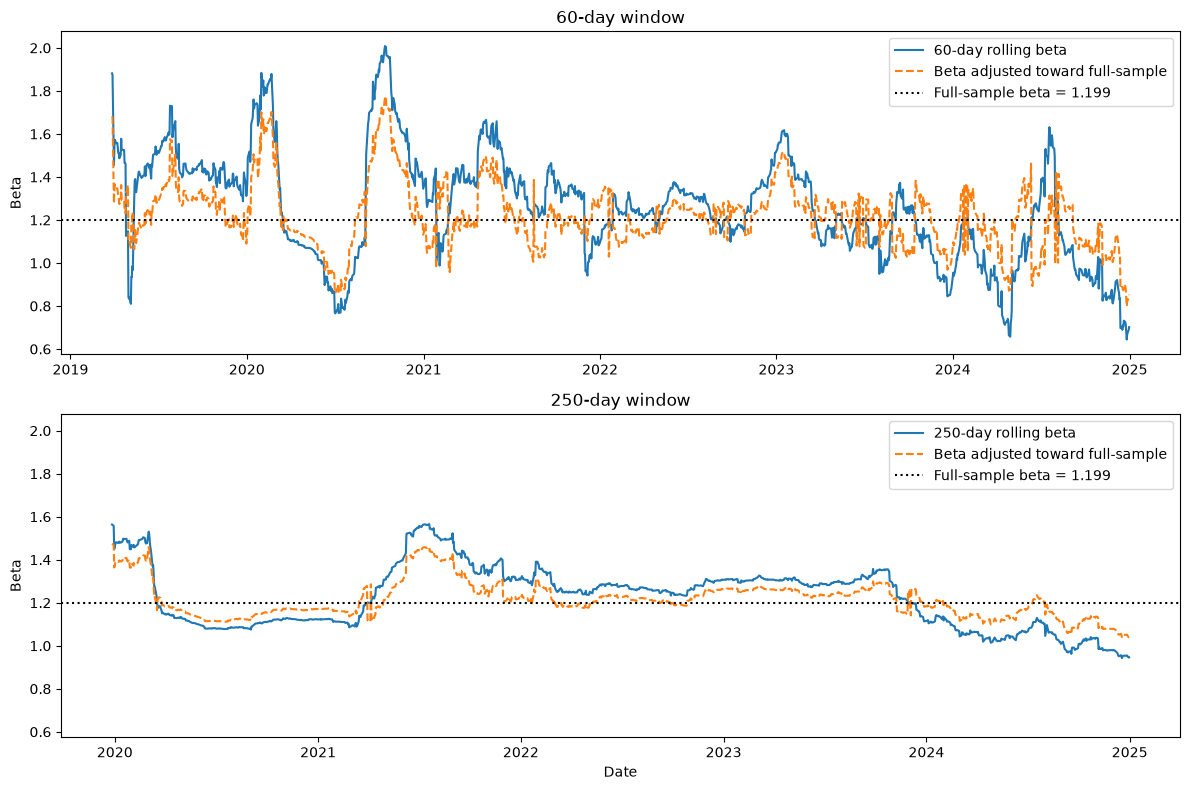

In [32]:
m = data['MKT']
r = data['AAPL']
beta_full = r.cov(m) / m.var()

fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharey=True)

for ax, window in zip(axs, [60, 250]):
    sxx = m.rolling(window).var() * (window - 1)
    syy = r.rolling(window).var() * (window - 1)
    sxy = r.rolling(window).cov(m) * (window - 1)

    beta = sxy / sxx
    residual_ss = (syy - sxy**2 / sxx).clip(lower=0)
    beta_se = ((residual_ss / (window - 2)) / sxx) ** 0.5

    # Move one SE toward the full-sample beta
    adjusted = beta - beta_se.where(beta > beta_full, -beta_se)

    ax.plot(beta.index, beta, label=f'{window}-day rolling beta')
    ax.plot(adjusted.index, adjusted, '--', label='Beta adjusted toward full-sample')
    ax.axhline(beta_full, color='black', linestyle=':', label=f'Full-sample beta = {beta_full:.3f}')
    ax.set_title(f'{window}-day window')
    ax.set_ylabel('Beta')
    ax.legend()

axs[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

**Answer:**
Not at all. From 2020 Feb to 2020 June, there is a sigficant decrease in beta. From 2020 June to 2020 Oct, there is a significant increase in beta. From 2024 to 2025, there is larger variance in rolling beta and the long-term trend seems to decrease. The largest movement occurs between 2020 June to 2020 Oct. With larger rolling window, it is more easy to identify the genuine trend but it also responses much slow. I would use 252 days estimation to hedge market exposure because it introduce less noise. Also, it seems to be more volatile these days.

## 5.3 Separate slopes for up and down markets

Allow a different slope on days when the market rises and on days when it falls:

$$r_t = \alpha + \beta^{+} \max(m_t, 0) + \beta^{-} \min(m_t, 0) + \varepsilon_t$$

**Task 5E.**

1. Estimate this model for each of the six stocks with HC1 standard errors. Report $\hat\beta^{+}$, $\hat\beta^{-}$, their difference, the t-statistic for $\beta^{+} = \beta^{-}$ (`t_test` in `statsmodels`), and the single $\hat\beta$ from `table`.
2. For AAPL, plot the returns against `MKT` with the two fitted slopes.

Reference: TSLA has $\hat\beta^{+} = 1.2179$, $\hat\beta^{-} = 1.8699$ and a t-statistic of -2.198.

,beta_plus,beta_minus,Difference (+ minus -),t-statistic,Single beta
Ticker,,,,,
AAPL,1.2208,1.1785,0.0423,0.5291,1.1986
AMZN,1.0602,1.1306,-0.0704,-0.3402,1.0972
GOOGL,1.1278,1.1554,-0.0277,-0.2870,1.1423
MSFT,1.2176,1.1501,0.0675,0.8640,1.1821
NVDA,1.8329,1.7525,0.0804,0.4754,1.7907
TSLA,1.2179,1.8699,-0.6521,-2.1980,1.5605


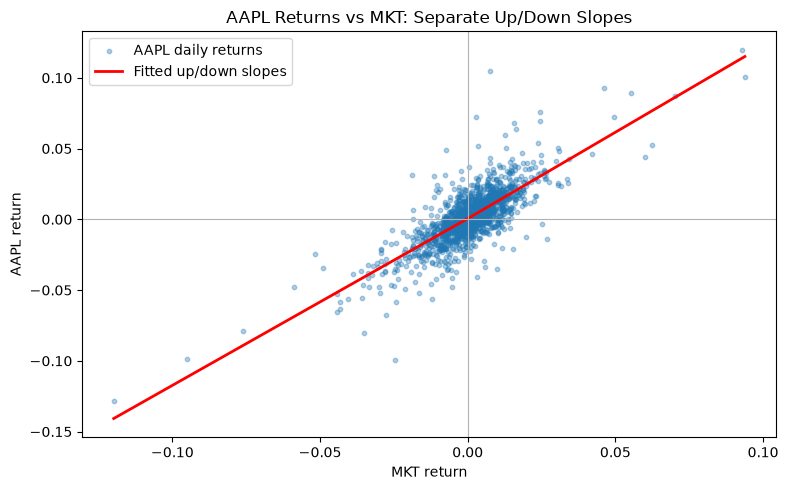

In [33]:
rows_5e = []
fits_5e = {}

m = data['MKT']

for ticker in tickers:
    X = pd.DataFrame({
        'MKT_pos': m.clip(lower=0),
        'MKT_neg': m.clip(upper=0),
    }, index=data.index)
    X = sm.add_constant(X)

    fit = sm.OLS(data[ticker], X).fit(cov_type='HC1')
    fits_5e[ticker] = fit

    equality_test = fit.t_test('MKT_pos = MKT_neg')

    rows_5e.append({
        'Ticker': ticker,
        'beta_plus': fit.params['MKT_pos'],
        'beta_minus': fit.params['MKT_neg'],
        'Difference (+ minus -)': fit.params['MKT_pos'] - fit.params['MKT_neg'],
        't-statistic': float(np.asarray(equality_test.tvalue).squeeze()),
        'Single beta': table.loc[ticker, 'beta'],
    })

table_5e = pd.DataFrame(rows_5e).set_index('Ticker')
display(table_5e.round(4))

# AAPL scatter and fitted piecewise regression
fit = fits_5e['AAPL']
x_grid = np.linspace(m.min(), m.max(), 300)
y_grid = (
    fit.params['const']
    + fit.params['MKT_pos'] * np.maximum(x_grid, 0)
    + fit.params['MKT_neg'] * np.minimum(x_grid, 0)
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(m, data['AAPL'], s=10, alpha=0.35, label='AAPL daily returns')
ax.plot(x_grid, y_grid, color='red', linewidth=2, label='Fitted up/down slopes')
ax.axhline(0, color='0.7', linewidth=0.8)
ax.axvline(0, color='0.7', linewidth=0.8)
ax.set_xlabel('MKT return')
ax.set_ylabel('AAPL return')
ax.set_title('AAPL Returns vs MKT: Separate Up/Down Slopes')
ax.legend()
plt.tight_layout()
plt.show()

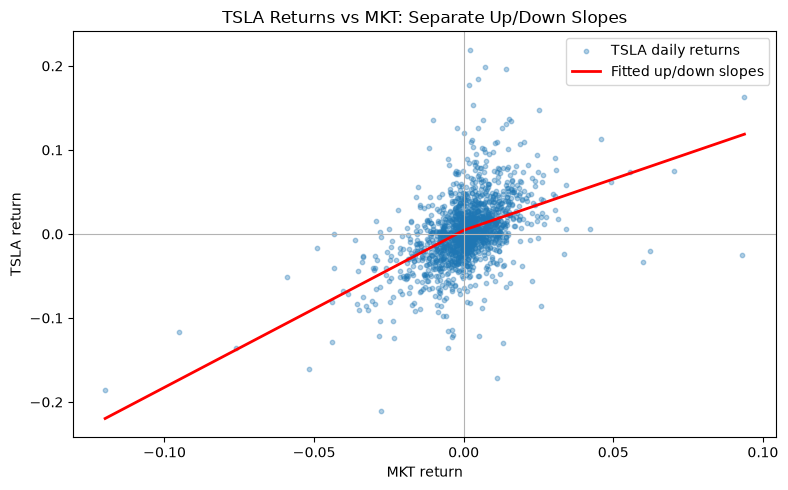

In [34]:
fit = fits_5e['TSLA']

x_grid = np.linspace(data['MKT'].min(), data['MKT'].max(), 300)
y_grid = (
    fit.params['const']
    + fit.params['MKT_pos'] * np.maximum(x_grid, 0)
    + fit.params['MKT_neg'] * np.minimum(x_grid, 0)
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(data['MKT'], data['TSLA'], s=10, alpha=0.35, label='TSLA daily returns')
ax.plot(x_grid, y_grid, color='red', linewidth=2, label='Fitted up/down slopes')
ax.axhline(0, color='0.7', linewidth=0.8)
ax.axvline(0, color='0.7', linewidth=0.8)
ax.set_xlabel('MKT return')
ax.set_ylabel('TSLA return')
ax.set_title('TSLA Returns vs MKT: Separate Up/Down Slopes')
ax.legend()
plt.tight_layout()
plt.show()

**Question 5.3**

Do the six stocks respond differently to up and down markets? Which differences are statistically meaningful and which are not? What does this imply about describing a stock's relation to the market with a single straight line?

**Answer:**
Only t-statistic for TSLA seems to be statistically signicant. For other stocks, single straight line will be a good enough approximation and separate slope will not contribute much to the predictability of the model.

As for TSLA case, I would say since the correlation between TSLA and market is low, the calculated beta is not that meaningful in either case.